# How close can an xG model built from Gold get to Understat's?

Expected goals (xG) is the chance a shot is scored. Understat publishes its own model's
value for every shot, and that is the benchmark here — never an input, since using it
would make the comparison circular. The target is simply whether the shot went in.

**What the model can see** is what Part 1's Gold layer carries about a shot: where it
was taken from (distance and angle to goal), the situation (open play, corner, set
piece, free kick), the body part, whether a pass set it up, home or away, and the
minute. **What it cannot see** is the action before the shot — a cross, a through ball,
a rebound — which Understat parses and uses, but which never reached Gold.

Penalties (one spot, one value) and own goals (not shots) are excluded and tested to be.

**How it was earned.** As for the match models: the setting was chosen on 2024/25,
then 2025/26 was walked forward month by month and scored once. Shots of one match are
never split between training and test, and every interval resamples **matches**, since
shots within a match are not independent. This notebook only reads
`reports/shot_xg.json`.

In [1]:
%matplotlib inline
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from football_ml import viz

viz.apply_style()
REPORTS = Path("..") / "reports"

report = json.loads((REPORTS / "shot_xg.json").read_text())
holdout = report["holdout"]
labels = {"model": "This model"}
names = viz.METHOD_NAMES | labels
print(report["citation"])
print(f"Hold-out {holdout['season']}: {holdout['shots']:,} shots in {holdout['matches']:,} matches")

features built from the Gold snapshot exported 2026-09-20T13:41:36+00:00, matches 2024-08-15 to 2026-09-19 (3,733 matches, 94,034 shots)
Hold-out 2025/26: 43,457 shots in 1,752 matches


## 1. The scores

Log loss and Brier score the probabilities (lower is better). AUC measures only the
ranking — how well goals are told from misses, 0.5 being a coin toss. The last two
columns compare the average predicted chance with the share of shots that went in.

In [2]:
table = (
    pd.DataFrame(holdout["scores"])
    .T[["log_loss", "brier", "auc", "mean_predicted", "observed_rate"]]
    .rename(index=names, columns={
        "log_loss": "log loss", "brier": "Brier", "auc": "AUC",
        "mean_predicted": "mean xG", "observed_rate": "goal rate",
    })
)
print(table.round(4).to_string())

                         log loss   Brier     AUC  mean xG  goal rate
Distance + angle           0.2912  0.0818  0.7191   0.1013     0.0987
This model                 0.2802  0.0791  0.7570   0.1007     0.0987
Understat, as published    0.2589  0.0733  0.7992   0.1151     0.0987
Understat, recalibrated    0.2563  0.0724  0.7991   0.1001     0.0987


Understat's published xG runs about 15% above the actual goal rate in these seasons.
A model calibrated on this data would beat it on log loss partly by being calibrated,
not by telling goals from misses any better. So the comparison that matters is against
**Understat recalibrated** — its xG passed through a two-parameter logistic correction
fitted on each training fold, which keeps its ranking of shots and removes the bias.

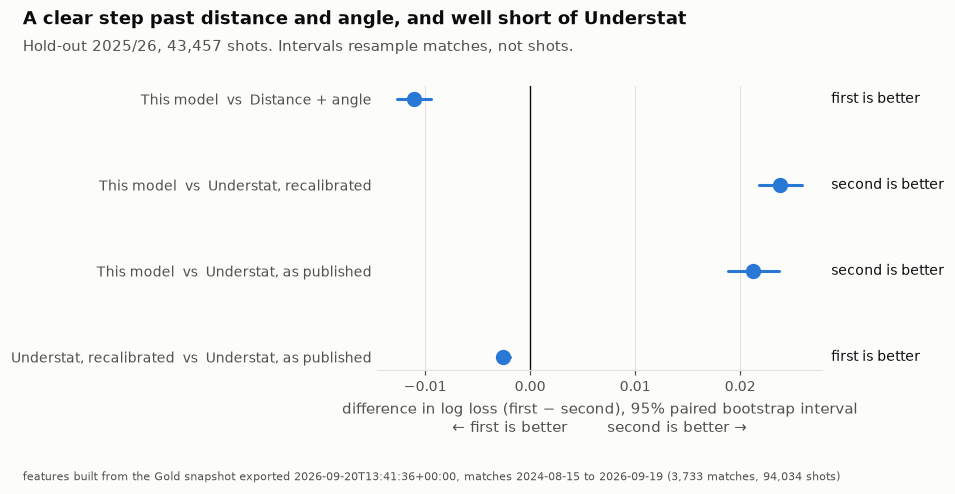

In [3]:
pairs = [
    ("model", "baseline"),
    ("model", "understat_recalibrated"),
    ("model", "understat"),
    ("understat_recalibrated", "understat"),
]
fig = viz.interval_plot(holdout["comparisons"], pairs, metric="log_loss", unit="log loss",
                        labels=labels)
viz.title_block(
    fig,
    "A clear step past distance and angle, and well short of Understat",
    "Hold-out 2025/26, 43,457 shots. Intervals resample matches, not shots.",
)
viz.annotate_source(fig, report["citation"])
plt.show()

## 2. Calibration

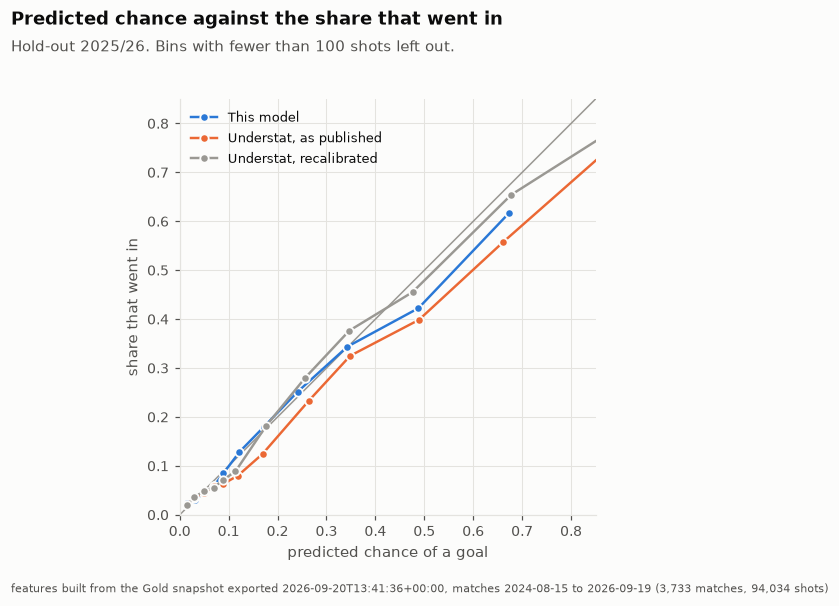

In [4]:
fig = viz.binary_reliability(
    holdout["calibration"], ["model", "understat", "understat_recalibrated"], labels=labels
)
viz.title_block(fig, "Predicted chance against the share that went in",
                "Hold-out 2025/26. Bins with fewer than 100 shots left out.")
viz.annotate_source(fig, report["citation"])
plt.show()

## 3. Where the gap is — and where it is not

If the gap to Understat comes from the action before the shot, it should be largest
where that action varies most, and absent where there is none. A direct free kick is
taken from a dead ball: there is no previous action to know about.

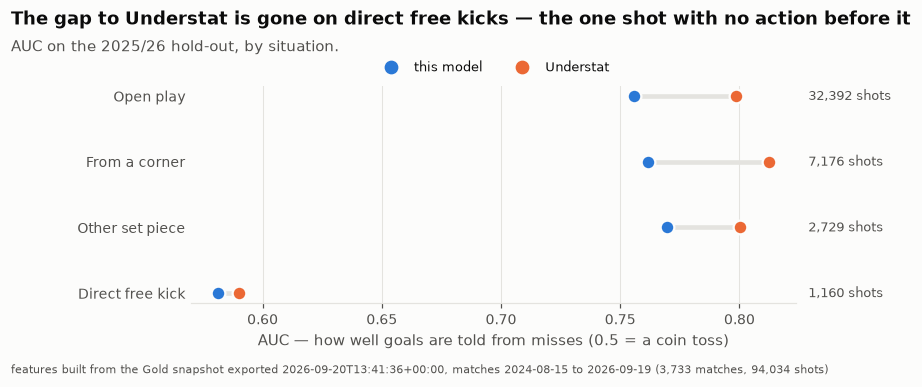

In [5]:
fig = viz.situation_dumbbell(holdout["by_situation"])
viz.title_block(
    fig,
    "The gap to Understat is gone on direct free kicks — the one shot with no action before it",
    "AUC on the 2025/26 hold-out, by situation.",
)
viz.annotate_source(fig, report["citation"])
plt.show()

## 4. What the model learned

The final model's chance of a goal over the attacking third, for two kinds of shot —
both assisted, at the 45th minute. Not a new fit: these are the fitted model's own
predictions on a grid, stored in the report.

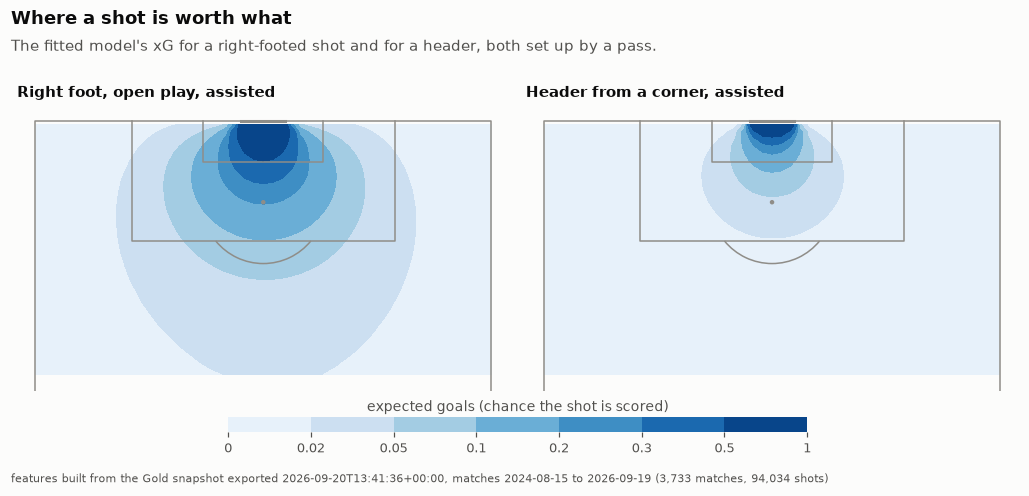

In [6]:
fig = viz.xg_surface(report["surface"])
viz.title_block(
    fig,
    "Where a shot is worth what",
    "The fitted model's xG for a right-footed shot and for a header, both set up by a pass.",
)
viz.annotate_source(fig, report["citation"])
plt.show()

## 5. Penalties, as a constant

In [7]:
pen = holdout["penalties"]
print(
    f"converted before the hold-out: {pen['before_holdout']['conversion']:.3f} "
    f"({pen['before_holdout']['penalties']} penalties)\n"
    f"converted in the hold-out:     {pen['holdout']['conversion']:.3f} "
    f"({pen['holdout']['penalties']} penalties)\n"
    f"Understat's xG for every one:  {pen['understat_xg']:.3f}"
)

converted before the hold-out: 0.789 (513 penalties)
converted in the hold-out:     0.773 (551 penalties)
Understat's xG for every one:  0.756


## Answer

**With what Gold carries, an xG model gets a clear step past distance and angle and
stays well short of Understat.** On the 2025/26 hold-out it improves on the
distance-and-angle baseline by 0.011 log loss (interval −0.0127 to −0.0095), and trails
Understat recalibrated by 0.024 (+0.0218 to +0.0259). The gap is in ranking — AUC 0.757
against 0.799 — not in calibration.

**The gap sits where the missing information would put it.** It is largest in open play
and from corners and gone on direct free kicks, the only situation with no action before
the shot. That is consistent with Gold lacking the action before the shot (a cross, a
through ball, a rebound), which Understat's model uses. Consistent with, not proof of:
there is no interval per situation, and there are only 1,160 free kicks.

**Understat's own xG is miscalibrated on these seasons** — 0.115 per shot against 0.099
scored — which is why the comparison is made against it recalibrated.

**Caveats.**
- Location is Understat's, normalised to [0, 1] and mapped onto a 105 × 68 m pitch; real
  grounds vary by a few metres.
- One hold-out season. The model was chosen among a logistic regression and histogram
  boosting on validation; boosting lost, and lost more the more capacity it had.
- Penalties are not modelled; own goals are not shots.
- Adding the action before the shot to Gold is a Part 1 change; it is recommended, not done.